# DCF Sensitivity Table

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

A two-way table of discounted-cash-flow value per share across discount rates (WACC) and terminal growth rates, colored relative to the current share price. It shows how much of a valuation depends on two assumptions that cannot be known precisely.

## When to use

- Show how sensitive an intrinsic valuation is to its key inputs
- Find the assumptions the current market price implies (the cells closest to gray)
- Support investment memos, equity research and M&A models

## Avoid when

- Coloring by raw value with a rainbow scale; color relative to a meaningful reference (price) with a diverging scale
- More than ~9×9 cells (readers cannot scan it); choose sensible step sizes

## Alternatives

- Tornado chart of one-at-a-time sensitivities
- Football field across methods

## Design tips

- Outline the base case cell
- Center the diverging scale on the current price so blue = upside and orange = downside
- Print values in every cell; this is a table first and a chart second
- Keep WACC above terminal growth everywhere (the Gordon growth formula breaks otherwise)

## Example

Five-year free-cash-flow forecast ($600m→$780m), $1.8bn net debt, 250M shares and a $38.50 share price; terminal value by the Gordon growth formula (illustrative).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

### Data

In [2]:
fcf = np.array([600, 650, 700, 740, 780.0])        # $m, years 1..5
net_debt, shares, price_now = 1800.0, 250.0, 38.50
waccs = np.round(np.arange(0.075, 0.1051, 0.005), 4)
growths = np.round(np.arange(0.010, 0.0301, 0.005), 4)


def value_per_share(wacc, g):
    t = np.arange(1, len(fcf) + 1)
    pv_fcf = (fcf / (1 + wacc) ** t).sum()
    terminal = fcf[-1] * (1 + g) / (wacc - g)       # Gordon growth, value at end of year 5
    ev = pv_fcf + terminal / (1 + wacc) ** len(fcf)
    return (ev - net_debt) / shares


table = pd.DataFrame([[value_per_share(w, g) for w in waccs] for g in growths],
                     index=[f"{g:.1%}" for g in growths], columns=[f"{w:.1%}" for w in waccs]).round(2)
base = ("2.0%", "8.5%")                             # (growth, WACC)
table

,7.5%,8.0%,8.5%,9.0%,9.5%,10.0%,10.5%
1.0%,37.70,34.41,31.57,29.08,26.88,24.93,23.19
1.5%,40.69,36.93,33.71,30.92,28.48,26.33,24.41
2.0%,44.23,39.87,36.18,33.02,30.29,27.89,25.78
2.5%,48.48,43.35,39.07,35.45,32.35,29.67,27.32
3.0%,53.67,47.52,42.48,38.29,34.74,31.70,29.06


### Plot

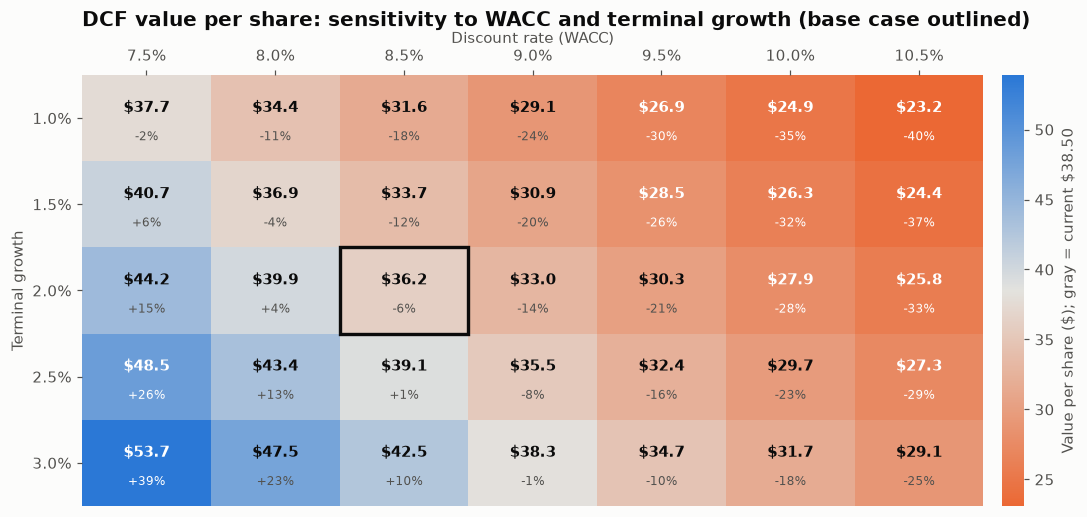

In [3]:
cmap = LinearSegmentedColormap.from_list("down_up", [PALETTE[1], "#e3e2de", PALETTE[0]])
z = table.to_numpy()
norm = TwoSlopeNorm(vmin=min(z.min(), price_now * 0.6), vcenter=price_now, vmax=max(z.max(), price_now * 1.4))
fig, ax = plt.subplots(figsize=(10, 4.8))
im = ax.imshow(z, cmap=cmap, norm=norm, aspect="auto")
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        v = z[i, j]
        far = abs(norm(v) - 0.5) > 0.32
        ax.text(j, i - 0.12, f"${v:.1f}", ha="center", va="center", fontsize=10, fontweight="bold",
                color="white" if far else "#0b0b0b")
        ax.text(j, i + 0.22, f"{v / price_now - 1:+.0%}", ha="center", va="center", fontsize=8,
                color="white" if far else "#52514e")
bi, bj = table.index.get_loc(base[0]), table.columns.get_loc(base[1])
ax.add_patch(plt.Rectangle((bj - 0.5, bi - 0.5), 1, 1, fill=False, edgecolor="#0b0b0b", linewidth=2.2))
ax.set_xticks(range(len(waccs)), table.columns)
ax.set_yticks(range(len(growths)), table.index)
ax.set_xlabel("Discount rate (WACC)")
ax.set_ylabel("Terminal growth")
ax.xaxis.set_label_position("top")
ax.xaxis.tick_top()
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cb.set_label(f"Value per share (\\$); gray = current \\${price_now:.2f}")
cb.outline.set_visible(False)
ax.set_title("DCF value per share: sensitivity to WACC and terminal growth (base case outlined)", pad=32)
fig.tight_layout()
plt.show()

## How to read it

Each cell is value per share for one WACC (column) and terminal growth (row), with the % up- or downside to $38.50 below it. The base case (8.5%, 2.0%) is outlined. Moving one column right lowers value by several dollars, a reminder that the discount rate drives most of the answer.

---
Standalone script: [`dcf_sensitivity_table.py`](dcf_sensitivity_table.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)